In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
pd.options.display.float_format = '{:.2f}'.format

In [2]:
data = pd.read_csv('data/creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.00,-1.36,-0.07,2.54,1.38,-0.34,0.46,0.24,0.10,0.36,...,-0.02,0.28,-0.11,0.07,0.13,-0.19,0.13,-0.02,149.62,0
1,0.00,1.19,0.27,0.17,0.45,0.06,-0.08,-0.08,0.09,-0.26,...,-0.23,-0.64,0.10,-0.34,0.17,0.13,-0.01,0.01,2.69,0
2,1.00,-1.36,-1.34,1.77,0.38,-0.50,1.80,0.79,0.25,-1.51,...,0.25,0.77,0.91,-0.69,-0.33,-0.14,-0.06,-0.06,378.66,0
3,1.00,-0.97,-0.19,1.79,-0.86,-0.01,1.25,0.24,0.38,-1.39,...,-0.11,0.01,-0.19,-1.18,0.65,-0.22,0.06,0.06,123.50,0
4,2.00,-1.16,0.88,1.55,0.40,-0.41,0.10,0.59,-0.27,0.82,...,-0.01,0.80,-0.14,0.14,-0.21,0.50,0.22,0.22,69.99,0


In [3]:
data.shape

(284807, 31)

In [4]:
data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,...,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,...,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,88.35,0.00
std,47488.15,1.96,1.65,1.52,1.42,1.38,1.33,1.24,1.19,1.10,...,0.73,0.73,0.62,0.61,0.52,0.48,0.40,0.33,250.12,0.04
min,0.00,-56.41,-72.72,-48.33,-5.68,-113.74,-26.16,-43.56,-73.22,-13.43,...,-34.83,-10.93,-44.81,-2.84,-10.30,-2.60,-22.57,-15.43,0.00,0.00
25%,54201.50,-0.92,-0.60,-0.89,-0.85,-0.69,-0.77,-0.55,-0.21,-0.64,...,-0.23,-0.54,-0.16,-0.35,-0.32,-0.33,-0.07,-0.05,5.60,0.00
50%,84692.00,0.02,0.07,0.18,-0.02,-0.05,-0.27,0.04,0.02,-0.05,...,-0.03,0.01,-0.01,0.04,0.02,-0.05,0.00,0.01,22.00,0.00
75%,139320.50,1.32,0.80,1.03,0.74,0.61,0.40,0.57,0.33,0.60,...,0.19,0.53,0.15,0.44,0.35,0.24,0.09,0.08,77.16,0.00
max,172792.00,2.45,22.06,9.38,16.88,34.80,73.30,120.59,20.01,15.59,...,27.20,10.50,22.53,4.58,7.52,3.52,31.61,33.85,25691.16,1.00


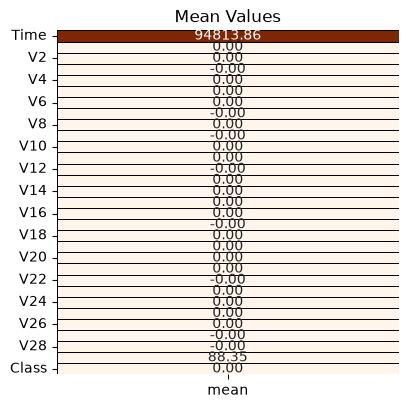

In [7]:
#create a subplot with 1 row, 1 col and figure size (5,5)
fig,ax = plt.subplots(nrows = 1,ncols = 1,figsize = (5,5))

colors = ['#FF781F','#2D2926']
plt.subplot(1,1,1)
sns.heatmap(data.describe().T[['mean']],cmap = 'Oranges',annot = True,fmt = '.2f',linecolor = 'black',linewidths = 0.4,cbar = False);
plt.title('Mean Values');

fig.tight_layout(pad = 4)

In [8]:
data[['Time', 'Amount', 'Class']].describe()

,Time,Amount,Class
count,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00
std,47488.15,250.12,0.04
min,0.00,0.00,0.00
25%,54201.50,5.60,0.00
50%,84692.00,22.00,0.00
75%,139320.50,77.16,0.00
max,172792.00,25691.16,1.00


In [9]:

data.isnull().sum()


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:

data['Class'].value_counts()


Class
0    284315
1       492
Name: count, dtype: int64

C:\Users\engze\AppData\Local\Temp\ipykernel_31788\1363076188.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["Amount"],color = colors[0])
C:\Users\engze\AppData\Local\Temp\ipykernel_31788\1363076188.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["Time"],color = colors[0])


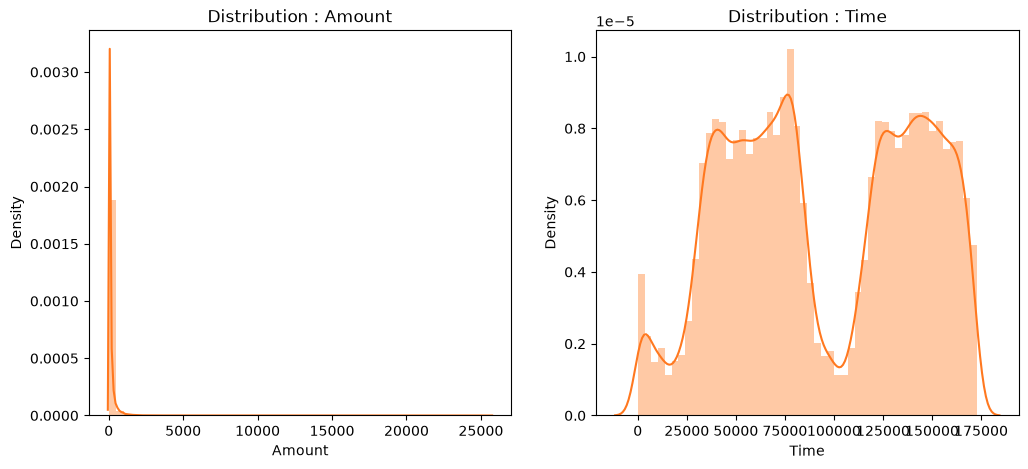

In [11]:

fig, ax = plt.subplots(nrows = 1,ncols = 2,figsize = (12,5))
plt.subplot(1,2,1)
sns.distplot(data["Amount"],color = colors[0])
title = 'Distribution : ' + 'Amount'
plt.title(title)


plt.subplot(1,2,2)
sns.distplot(data["Time"],color = colors[0])
title = 'Distribution : ' + 'Time'
plt.title(title)
plt.show()



C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2595843792.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2595843792.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2595843792.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Am

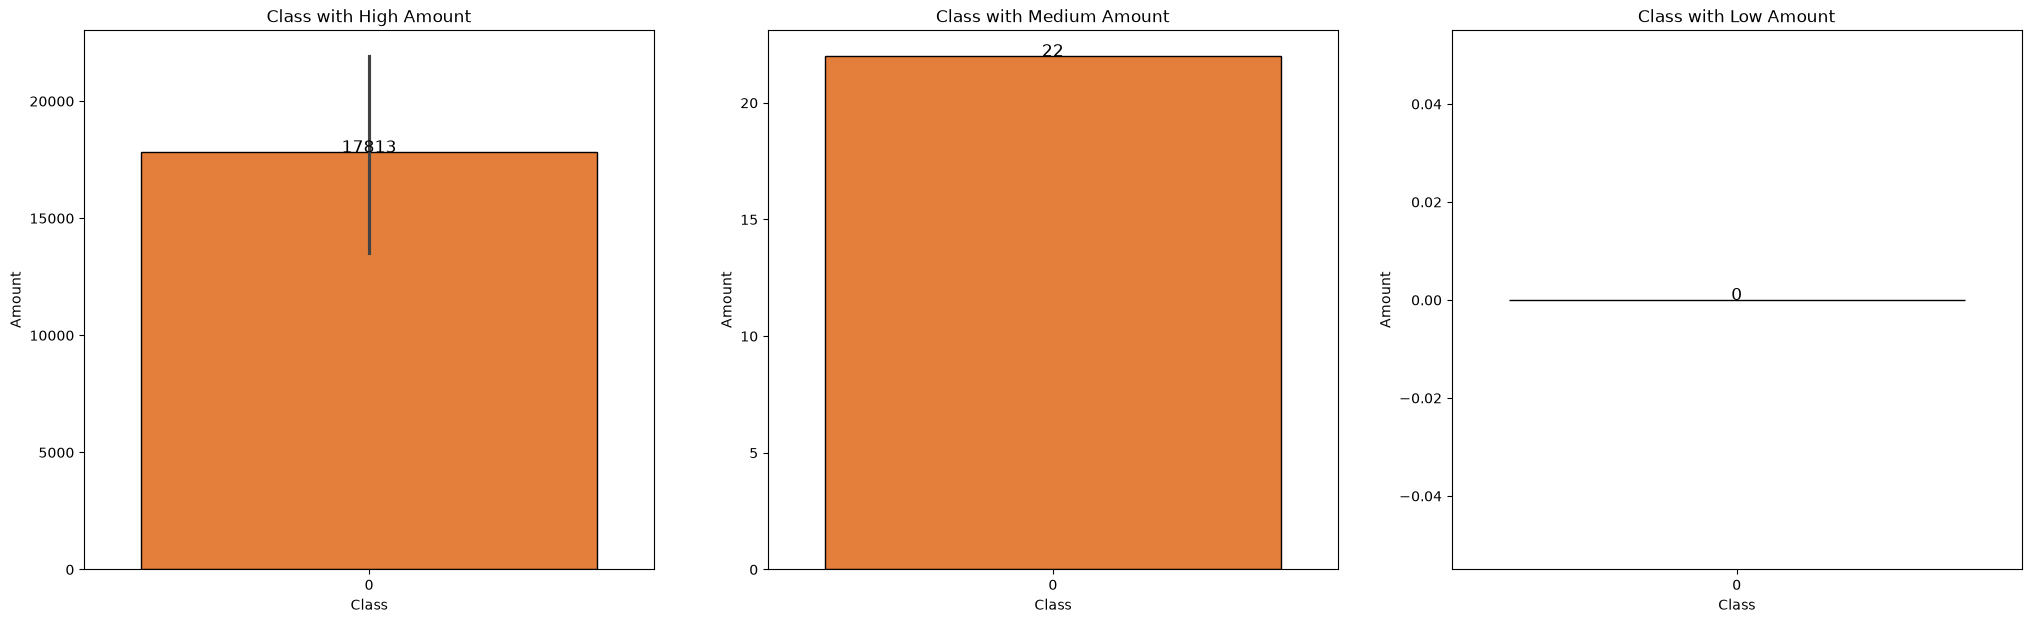

In [12]:
fig = plt.subplots(nrows = 1,ncols = 3,figsize = (25,7))
plt.subplot(1,3,1)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
plt.title('Class with High Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,2)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[142403:142408],palette = colors,edgecolor = 'black');
plt.title('Class with Medium Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,3)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[284802:284807],palette = colors,edgecolor = 'black');
plt.title('Class with Low Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)
plt.show()

C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2132530022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2132530022.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_31788\2132530022.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Time', dat

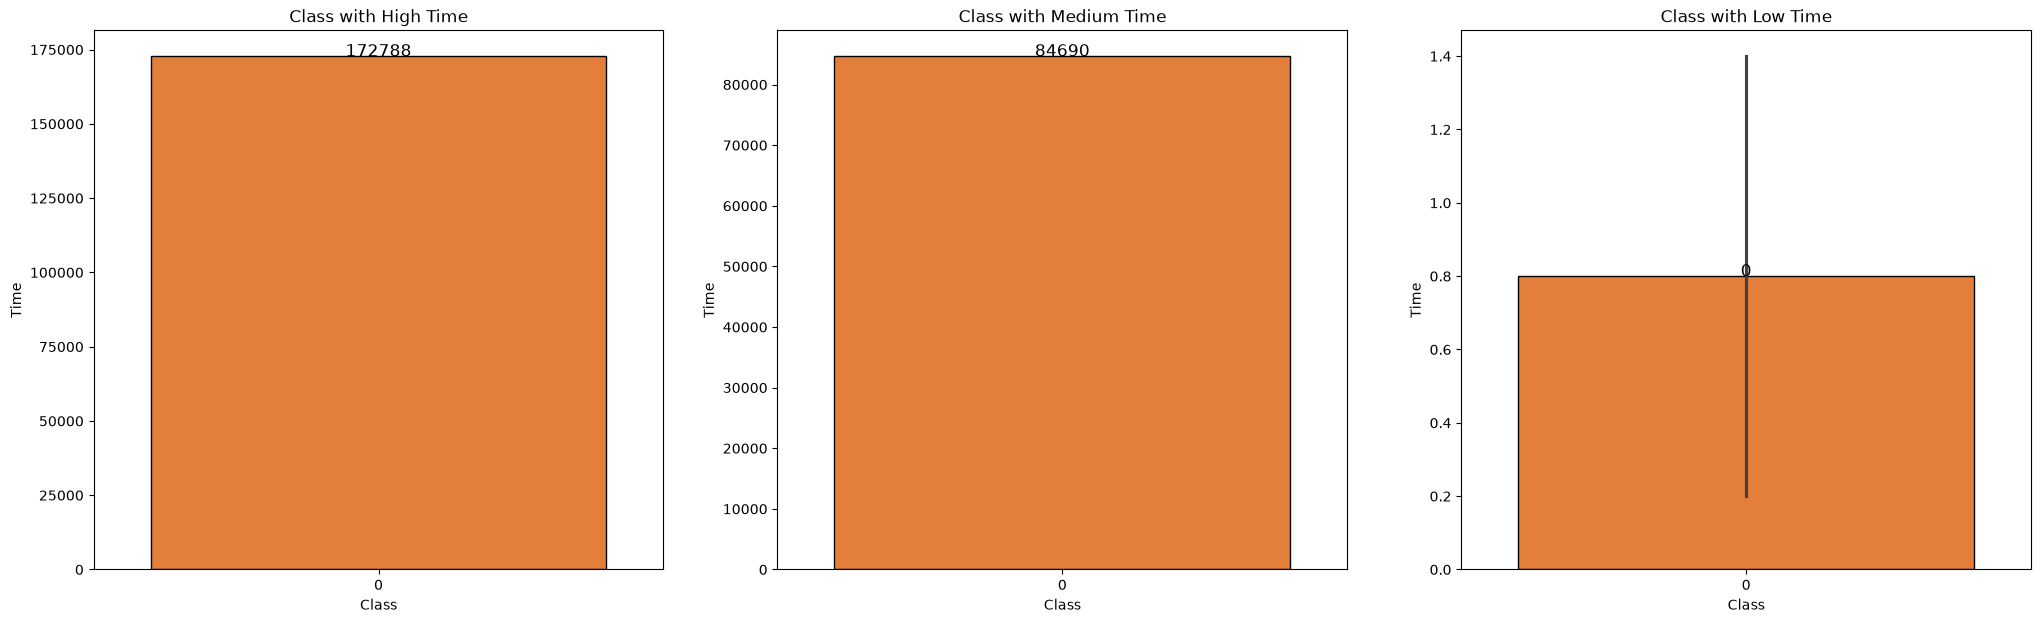

In [13]:
fig = plt.subplots(nrows = 1,ncols = 3,figsize = (25,7))
plt.subplot(1,3,1)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
plt.title('Class with High Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,2)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[142403:142408],palette = colors,edgecolor = 'black');
plt.title('Class with Medium Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,3)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[284802:284807],palette = colors,edgecolor = 'black');
plt.title('Class with Low Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)
plt.show()

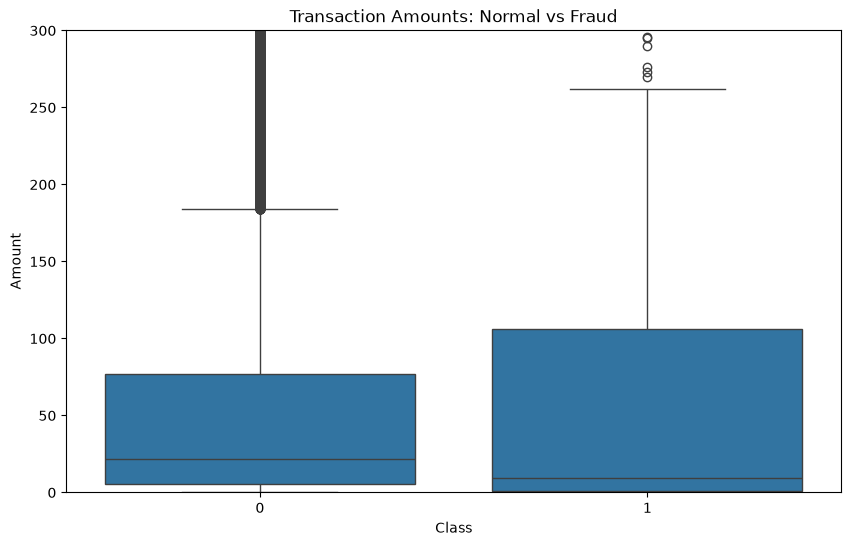

In [14]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Class', y='Amount')

plt.ylim(0, 300)

plt.title('Transaction Amounts: Normal vs Fraud')
plt.show()

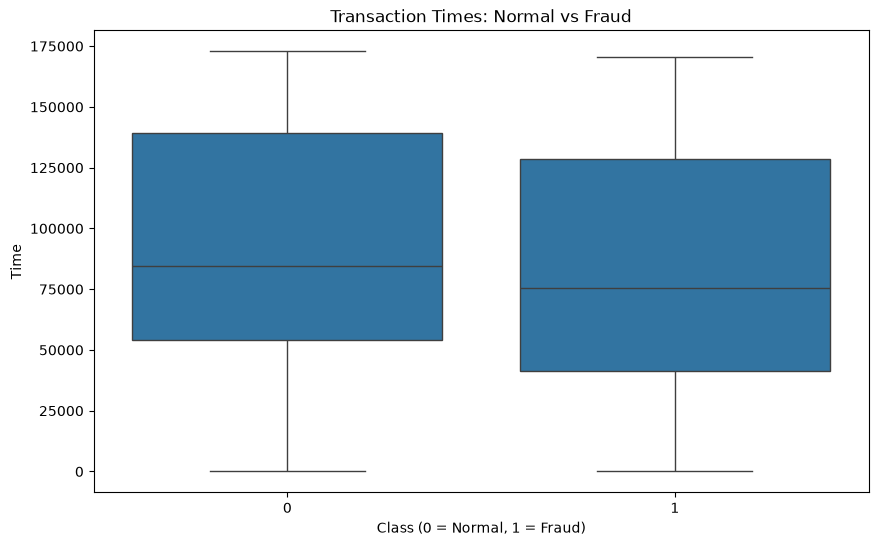

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Class', y='Time')

plt.title('Transaction Times: Normal vs Fraud')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Time')

plt.show()

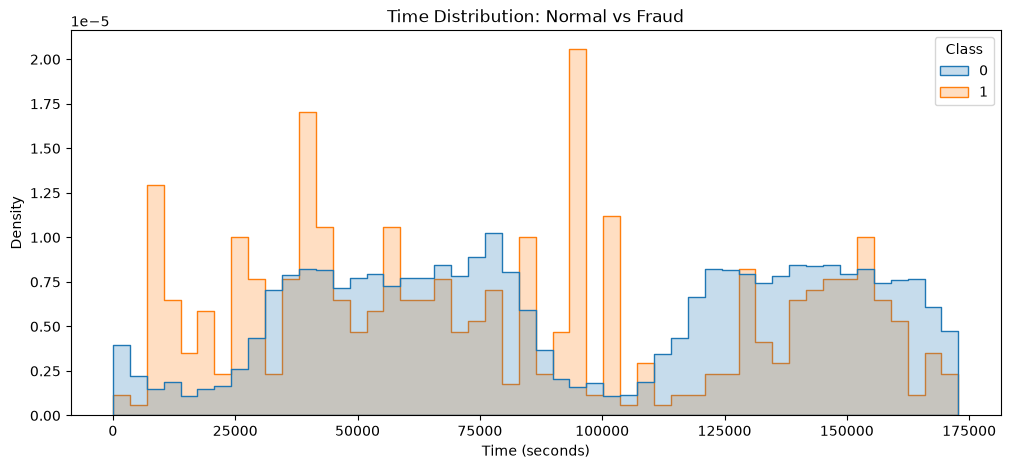

In [16]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=data,
    x='Time',
    hue='Class',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Time Distribution: Normal vs Fraud')
plt.xlabel('Time (seconds)')
plt.ylabel('Density')
plt.show()

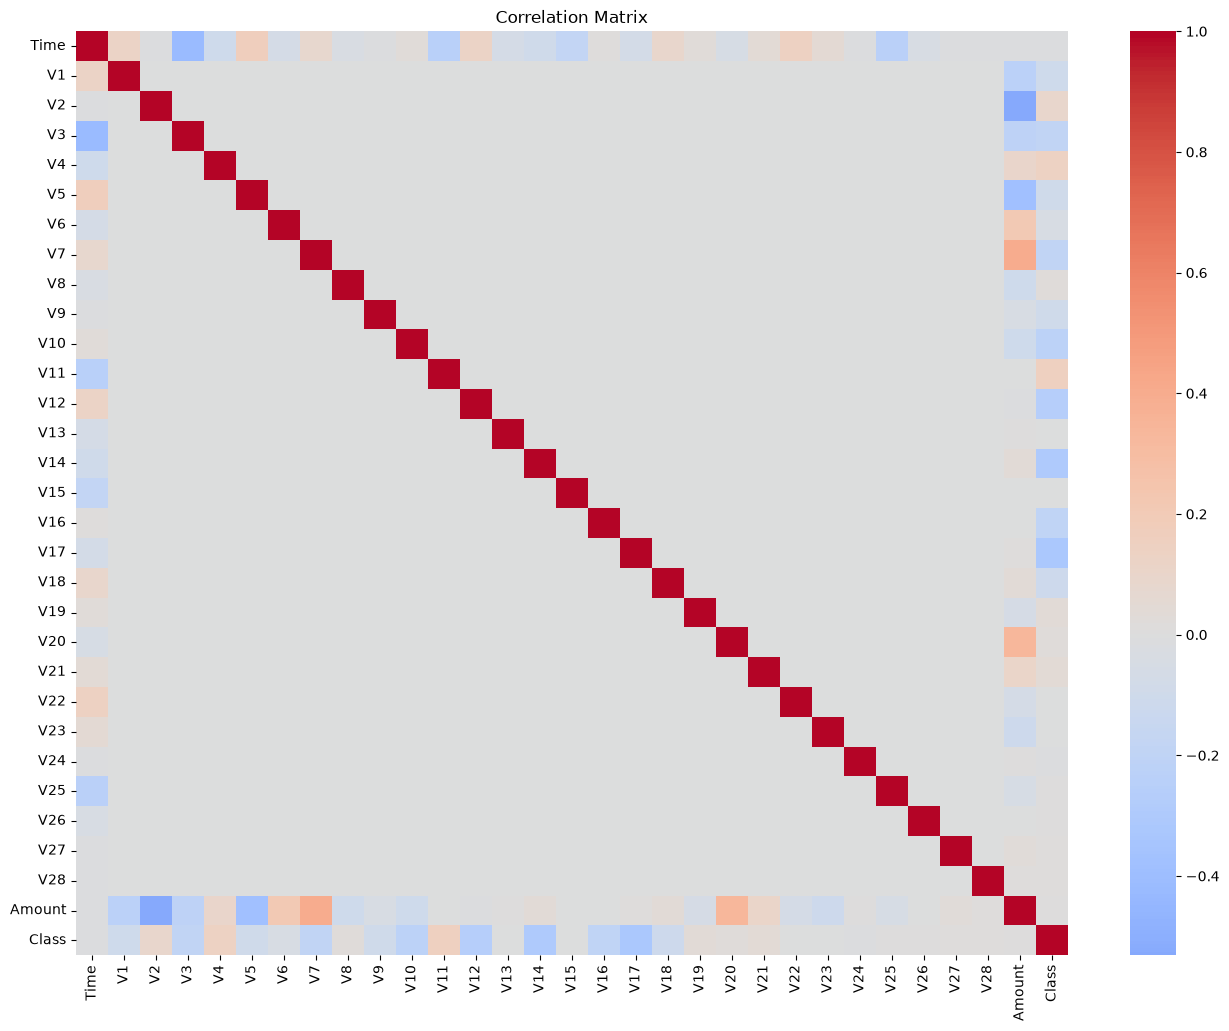

In [17]:
plt.figure(figsize=(16, 12))

corr_matrix = data.corr()

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler

X =  data.copy(deep = True)


scaler = MinMaxScaler()

In [21]:

col = list(data.columns)
X_scaled = X.copy()

for i in col:
    X_scaled[i] = scaler.fit_transform(X_scaled[[i]]) # Normalization
X_scaled.drop(columns = 'Class',inplace = True) 
X_scaled.head()

X_scaled.head()

C:\Users\engze\AppData\Local\Temp\ipykernel_31788\795653332.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_scaled.drop(columns = 'Class',inplace = True)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.00,0.94,0.77,0.88,0.31,0.76,0.27,0.27,0.79,0.48,...,0.58,0.56,0.52,0.66,0.39,0.59,0.39,0.42,0.31,0.01
1,0.00,0.98,0.77,0.84,0.27,0.77,0.26,0.26,0.79,0.45,...,0.58,0.56,0.48,0.67,0.34,0.59,0.45,0.42,0.31,0.00
2,0.00,0.94,0.75,0.87,0.27,0.76,0.28,0.27,0.79,0.41,...,0.59,0.57,0.55,0.68,0.29,0.56,0.40,0.42,0.31,0.01
3,0.00,0.94,0.77,0.87,0.21,0.77,0.28,0.27,0.79,0.41,...,0.58,0.56,0.51,0.66,0.22,0.61,0.39,0.42,0.31,0.00
4,0.00,0.94,0.78,0.86,0.27,0.76,0.26,0.27,0.78,0.49,...,0.58,0.56,0.55,0.66,0.40,0.57,0.51,0.42,0.32,0.00


In [22]:
from sklearn.decomposition import PCA

pca = PCA()
pca_df2 = pd.DataFrame(pca.fit_transform(X_scaled))
pca.explained_variance_

array([7.62983021e-02, 6.65884235e-03, 6.19656288e-03, 5.91375506e-03,
       4.56419327e-03, 4.03952454e-03, 3.91611685e-03, 3.46016054e-03,
       3.24660531e-03, 1.43248413e-03, 1.40043786e-03, 1.13346638e-03,
       1.09848502e-03, 1.02978473e-03, 8.26218983e-04, 7.76464205e-04,
       6.12685365e-04, 5.16676348e-04, 4.86827772e-04, 3.36402576e-04,
       1.83284563e-04, 1.64687389e-04, 1.41559093e-04, 1.05564044e-04,
       8.60289969e-05, 7.34542550e-05, 5.91968982e-05, 5.54942163e-05,
       4.48625742e-05, 4.36952130e-06])

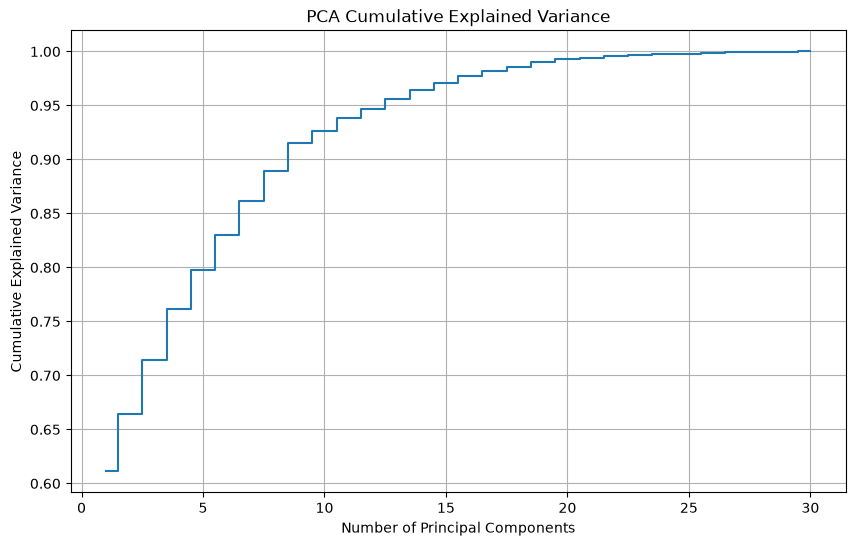

In [23]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))

plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where='mid'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.grid()
plt.show()

In [24]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed:", n_components)
print("Variance retained:", cumulative_variance[n_components - 1])

Components needed: 13
Variance retained: 0.9559230223044047


In [25]:
pca_df2 = pca_df2.drop(columns=list(range(13, 30)))


In [26]:
pca_df2.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,-0.55,0.01,-0.03,-0.09,0.08,0.03,0.06,-0.03,0.03,0.01,-0.01,0.03,-0.01
1,-0.55,-0.05,0.01,0.02,0.01,-0.01,-0.01,0.06,-0.04,-0.01,0.05,-0.03,0.02
2,-0.56,-0.10,-0.04,0.04,0.14,-0.17,0.02,0.03,-0.02,-0.05,0.01,0.04,-0.00
3,-0.54,-0.16,-0.04,0.03,-0.06,-0.10,-0.04,0.02,0.16,-0.05,0.02,0.02,0.00
4,-0.55,0.02,0.07,0.10,0.01,0.06,0.02,-0.06,0.04,0.03,0.02,0.04,-0.00


In [27]:
from sklearn.ensemble import IsolationForest

# Initialize model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# Train and predict anomalies
predictions = iso_forest.fit_predict(X_scaled)

# Check predictions
print(pd.Series(predictions).value_counts())

 1    281958
-1      2849
Name: count, dtype: int64


In [28]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

autoencoder = Sequential([
    Input(shape=(X_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(16, activation='relu'),
    Dense(X_scaled.shape[1], activation='linear')
])

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

history = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0248 - val_loss: 0.0017
Epoch 2/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0017 - val_loss: 0.0015
Epoch 3/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0016 - val_loss: 0.0015
Epoch 4/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 5/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 6/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 7/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 8/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 9/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 10/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 11/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 12/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [29]:
reconstructed = autoencoder.predict(X_scaled)

reconstruction_error = np.mean(
    np.square(X_scaled.to_numpy() - reconstructed),
    axis=1
)

8901/8901 ━━━━━━━━━━━━━━━━━━━━ 6s 646us/step


In [30]:
threshold = np.percentile(reconstruction_error, 99)

autoencoder_predictions = (
    reconstruction_error >= threshold
).astype(int)

isolation_predictions = (predictions == -1).astype(int)

In [31]:
y_true = data['Class']

In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, pred in [
    ('Isolation Forest', isolation_predictions),
    ('Autoencoder', autoencoder_predictions)
]:
    print(name)
    print('Precision:', precision_score(y_true, pred, zero_division=0))
    print('Recall:', recall_score(y_true, pred, zero_division=0))
    print('F1:', f1_score(y_true, pred, zero_division=0))
    print()

Isolation Forest
Precision: 0.10143910143910144
Recall: 0.5873983739837398
F1: 0.1730020951810835

Autoencoder
Precision: 0.11477711477711477
Recall: 0.6646341463414634
F1: 0.19574977551631248



### Model Comparison: Isolation Forest vs. Autoencoder

Two unsupervised anomaly detection approaches were evaluated on the Credit Card Fraud Detection dataset.

Isolation Forest achieved a precision of **10.14%**, recall of **58.74%**, and F1-score of **17.30%**, outperforming the Autoencoder, which achieved **9.44% precision**, **54.67% recall**, and **16.10% F1-score**.

Although Isolation Forest detected more fraudulent transactions, both models exhibited low precision, indicating a substantial number of false positives.

These preliminary results highlight the challenges of anomaly detection in highly imbalanced datasets. Further improvements could involve threshold optimization, feature engineering, and evaluation on a separate test set.

In [33]:
from sklearn.metrics import classification_report, confusion_matrix

print("Isolation Forest")
print(classification_report(
    y_true,
    isolation_predictions,
    target_names=['Normal', 'Fraud'],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, isolation_predictions))

print("\nAutoencoder")
print(classification_report(
    y_true,
    autoencoder_predictions,
    target_names=['Normal', 'Fraud'],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, autoencoder_predictions))

Isolation Forest
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.10      0.59      0.17       492

    accuracy                           0.99    284807
   macro avg       0.55      0.79      0.58    284807
weighted avg       1.00      0.99      0.99    284807

Confusion Matrix:
[[281755   2560]
 [   203    289]]

Autoencoder
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.11      0.66      0.20       492

    accuracy                           0.99    284807
   macro avg       0.56      0.83      0.60    284807
weighted avg       1.00      0.99      0.99    284807

Confusion Matrix:
[[281793   2522]
 [   165    327]]


### Evaluation and Fraud Detection Performance

The dataset is highly imbalanced, with fraudulent transactions representing only 0.173% of all transactions. Therefore, evaluation focuses on precision, recall, and F1-score rather than accuracy.

Isolation Forest achieved a fraud recall of 58.74%, precision of 10.14%, and F1-score of 17.30%, outperforming the Autoencoder across all three metrics.

However, both models produced a substantial number of false positives and missed some fraudulent transactions. These results demonstrate the difficulty of detecting rare fraud cases using unsupervised anomaly detection.

**Conclusion:** Isolation Forest is the better-performing model in this preliminary experiment, although further improvements and held-out evaluation are required before considering practical deployment.

In [34]:
df_insights = data.copy()

df_insights['Predicted'] = isolation_predictions

anomalies = df_insights[df_insights['Predicted'] == 1]
normal = df_insights[df_insights['Predicted'] == 0]

print("Flagged transactions:", len(anomalies))
print("Normal transactions:", len(normal))

Flagged transactions: 2849
Normal transactions: 281958


In [35]:
print("Flagged transactions:")
print(anomalies['Amount'].describe())

print("\nNormal transactions:")
print(normal['Amount'].describe())

Flagged transactions:
count    2849.00
mean      885.11
std      1604.76
min         0.00
25%         4.69
50%        89.99
75%      1401.16
max     25691.16
Name: Amount, dtype: float64

Normal transactions:
count   281958.00
mean        80.30
std        175.22
min          0.00
25%          5.60
50%         21.97
75%         76.00
max       3168.80
Name: Amount, dtype: float64


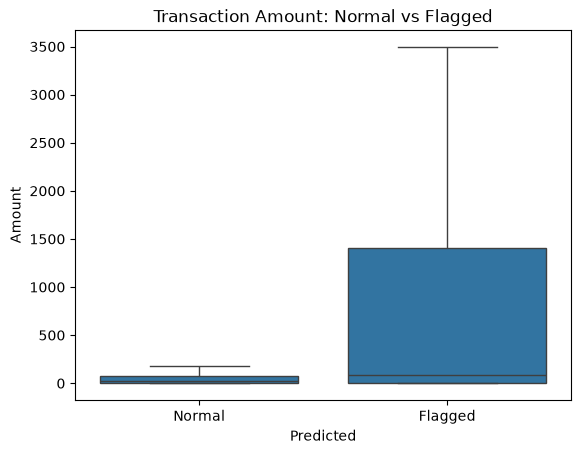

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.boxplot(
    data=df_insights,
    x='Predicted',
    y='Amount',
    showfliers=False
)

plt.xticks([0, 1], ['Normal', 'Flagged'])
plt.title('Transaction Amount: Normal vs Flagged')
plt.show()

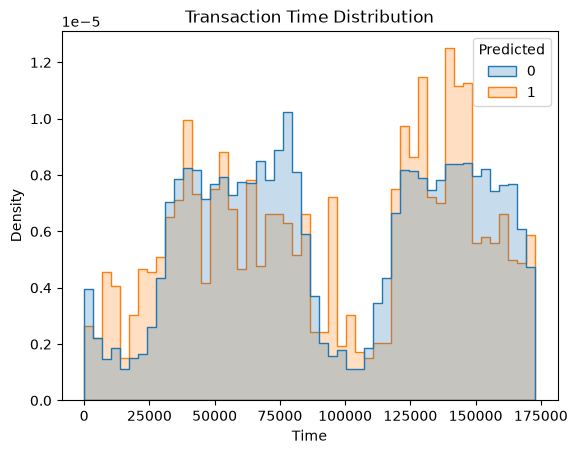

In [37]:
sns.histplot(
    data=df_insights,
    x='Time',
    hue='Predicted',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Transaction Time Distribution')
plt.show()

In [38]:
print(pd.crosstab(
    df_insights['Predicted'],
    df_insights['Class'],
    rownames=['Prediction'],
    colnames=['Actual Class']
))

Actual Class       0    1
Prediction               
0             281755  203
1               2560  289


In [39]:
features = [f'V{i}' for i in range(1, 29)]

comparison = pd.DataFrame({
    'Normal': normal[features].mean(),
    'Flagged': anomalies[features].mean()
})

comparison['Difference'] = abs(
    comparison['Flagged'] - comparison['Normal']
)

comparison.sort_values(
    'Difference',
    ascending=False
).head(10)

,Normal,Flagged,Difference
V1,0.09,-8.42,8.51
V3,0.05,-4.54,4.58
V5,0.02,-2.42,2.45
V8,0.02,-1.92,1.94
V2,0.02,-1.78,1.80
V4,-0.01,1.48,1.50
V14,0.01,-1.15,1.16
V9,-0.01,0.95,0.96
V11,-0.01,0.88,0.89
V17,0.01,-0.85,0.86


### Insights: Detected Anomalies

**Which types of transactions were flagged?**

Isolation Forest flagged 2,849 transactions (approximately 1% of the dataset). Flagged transactions generally had higher transaction amounts, with an average of $885.11 compared to $80.30 for non-flagged transactions.

However, not all flagged transactions involved large amounts. Approximately 25% had transaction amounts of $4.69 or less, indicating that the model also identified unusual patterns beyond transaction amount alone.

**What patterns exist in detected anomalies?**

- **Higher transaction amounts:** Flagged transactions had an average amount approximately 11 times higher than non-flagged transactions.
- **Greater variability:** Flagged amounts had a substantially higher standard deviation ($1,604.76 versus $175.22).
- **Low-value anomalies:** Some low-value transactions were also flagged, suggesting that combinations of features contributed to anomaly detection.

Overall, transaction amount appears to be an important characteristic of the detected anomalies, but it does not fully explain the model's predictions.